# Example: Stress-Testing the Utility Basket and Betting Against Beta
In this example, we stress-test two strategies from [the strategy menu](strategies/CHEME-5660-L15a-Strategy-Menu-Fall-2026.ipynb) on 200 synthetic markets. Each market is the real history to November 24, 2026, followed by one synthetic year of 252 trading days.

The two strategies share a picking rule and differ only in the weighting rule. You can choose any picking rule and any two weighting rules on the menu when you set the constants. We start with the same two strategies as the [real-market backtest](CHEME-5660-L15a-Example-Strategy-Backtest-Fall-2026.ipynb): the utility basket as our strategy and betting against beta (BAB) as the second strategy.

We plot the range of each strategy's wealth and test both strategies with the five gates. Then we test our strategy again with the market hedge on.

> __Learning Objectives:__
>
> By the end of this example, you should be able to:
> * __Plot the range of outcomes:__ Plot the percentiles of each strategy's wealth over the 200 synthetic markets, and compare them with those of the same investment in `SPY`.
> * __Test two strategies with the five gates:__ Compute the five gates of both strategies, test each gate against its limit, and measure the losses on the worst markets.
> * __Turn the market hedge on:__ Test the utility basket with the market hedge on, and compare its gates with those of the utility basket without the hedge.

Let's get started!

___

## Setup, Data, and Prerequisites
First, we set up the computational environment by including the `Include.jl` file and loading any needed resources.

> __Include:__ The [`include(...)` command](https://docs.julialang.org/en/v1/base/base/#include) evaluates the contents of the input source file, `Include.jl`, in the notebook's global scope. The `Include.jl` file sets paths, loads required external packages, and loads the functions in the local `src` directory. It also loads the strategy files in the `strategies` folder and [the strategy menu](strategies/menu.jl).

Let's set up our code environment:

In [1]:
include(joinpath(@__DIR__, "Include.jl")); # include the Include.jl file

  Activating 

project at `~/Desktop/julia_work/CHEME-5660-CourseRepository-Fall-2026`


[ Info: Precompiling Plots [91a5bcdd-55d7-5caf-9e0b-520d859cae80](cache misses: wrong dep version loaded (9))


[ Info: Precompiling Plots [91a5bcdd-55d7-5caf-9e0b-520d859cae80] (cache misses: wrong dep version loaded (18))



SYSTEM: caught exception of type :MethodError while trying to print a failed Task notice; giving up

SYSTEM: caught exception of type :MethodError while trying to print a failed Task notice; giving up


[ Info: Precompiling IJuliaExt [64482eec-cc57-5312-bea1-9f24eb636db7](cache misses: wrong dep version loaded (5), incompatible header (4))


... (9 outputs left out)


SYSTEM: caught exception of type :MethodError while trying to print a failed Task notice; giving up



SYSTEM: caught exception of type :MethodError while trying to print a failed Task notice; giving up

SYSTEM: caught exception of type :MethodError while trying to print a failed Task notice; giving up

SYSTEM: caught exception of type :MethodError while trying to print a failed Task notice; giving up



SYSTEM: caught exception of type :MethodError while trying to print a failed Task notice; giving up



SYSTEM: caught exception of type :MethodError while trying to print a failed Task notice; giving up

SYSTEM: caught exception of type :MethodError while trying to print a failed Task notice; giving up


For additional information on functions and types used in this material, see the [Julia programming language documentation](https://docs.julialang.org/en/v1/) and the [CHEME 5660 Quantitative Finance Package documentation](https://varnerlab.org/CHEME-5660-CourseRepository-Fall-2026/dev/).

### Data
The stress test ran every strategy on the menu on the 200 synthetic markets. With 5 seeds for each random picking rule, the menu has 756 stress tests. We load the saved results with [the `JLD2.load(...)` function](https://juliaio.github.io/JLD2.jl/stable/basic_usage/#FileIO-interface).

Market `p` uses the seed `5660 + p`, the seed of the practicum's stress test. On each market, a strategy makes its first decision after the close of November 24, 2026, and trades for the 252 synthetic days.

We store the saved results in five variables:
* The `stress_runs::DataFrame` variable holds one row per strategy and market. Each row holds the strategy's choices, the market's number in the `path_id` column, and the strategy's scores on that market, for example its Sharpe ratio, its largest drawdown, its wealth on the last day, and its net present value (NPV).
* The `synthetic_dates::Vector{Date}` variable holds November 24, 2026, and then the 252 synthetic trading days. The `spy_closes::Matrix{Float64}` and `tlt_closes::Matrix{Float64}` variables hold the closing prices of `SPY` and of the long-term Treasury bond fund `TLT` on these days (days × markets, USD/share).
* The `wealth_bands::Dict{String, Matrix{Float32}}` variable holds, for each strategy, the 5th, 25th, 50th, 75th, and 95th percentiles of its wealth on each day over the markets (days × percentiles, USD).

In [2]:
stress_runs, synthetic_dates, spy_closes, tlt_closes, wealth_bands = let

    # load the saved stress test of every strategy on the menu -
    saved = JLD2.load(joinpath(_PATH_TO_DATA, "L15a-Strategies-Synthetic.jld2"));
    stress_runs = saved["summary"];
    synthetic_dates = saved["dates"];
    spy_closes = Float64.(saved["spy"]);
    tlt_closes = Float64.(saved["tlt"]);
    wealth_bands = saved["bands"];

    # checks -
    @assert synthetic_dates[1] == Date(2026, 11, 24) && length(synthetic_dates) == 253 "the markets must start on 2026-11-24 and run 252 synthetic days"
    @assert size(spy_closes) == (253, 200) && size(tlt_closes) == (253, 200) "one close per day and market"
    @assert all(stress_runs.status .== "ok") "every saved run must have run without an error"

    # return -
    stress_runs, synthetic_dates, spy_closes, tlt_closes, wealth_bands
end;
println("$(nrow(stress_runs)) saved runs on $(maximum(stress_runs.path_id)) markets, $(synthetic_dates[2]) to $(synthetic_dates[end])");

151200 saved runs on 200 markets, 2026-11-25 to 2027-11-26


### Constants
Next, let's set the constants. See the comments next to the constants for definitions, units, and permissible values. The names on the menu are listed in [the strategy menu](strategies/CHEME-5660-L15a-Strategy-Menu-Fall-2026.ipynb):

In [3]:
my_picking = "gamma by sector"; # the picking rule of both strategies: a name on the picking menu, for example "liquid gamma"
my_weighting = "Cobb-Douglas"; # the weighting rule of our strategy (Cobb-Douglas gives the utility basket): a name on the weighting menu
second_weighting = "BAB"; # the weighting rule of the second strategy, which uses the same picking rule: a name on the weighting menu
my_estimates = "fixed"; # "fixed" keeps the 2016 to 2024 estimates, and "updated" updates them on each trading day
my_seed = 5660; # seed of the strategy's random draws: 5660, or 1 to 5 with a random picking rule (the saved seeds)
W0 = 100000.0; # starting wealth of the saved runs (USD), which must stay 100000.0 to match them
sharpe_limit = 0.3; # gate 1: the smallest median Sharpe ratio that passes (dimensionless)
drawdown_limit = 0.25; # gate 2: the largest median drawdown that passes (fraction of the peak wealth)
failure_limit = 0.10; # gate 3: the largest share of markets ending below W0 that passes
tail_level = 0.95; # level of the value at risk and the conditional value at risk: a share between 0 and 1
half_spread = 0.0005; # half bid-ask spread of each trade of the 60/40 benchmark (fraction of the trade's value)

___

## Task 1: Plot the Range of Outcomes
In this task, we plot the range of the wealth of both strategies over the 200 synthetic markets, and compare it with the same investment in `SPY`.

We compute the same percentiles for `SPY` with [the `quantile(...)` function](https://docs.julialang.org/en/v1/stdlib/Statistics/#Statistics.quantile). We store the percentiles of our strategy in the `strategy_band::Matrix{Float64}` variable, those of the second strategy in the `second_band::Matrix{Float64}` variable, and those of `SPY` in the `spy_band::Matrix{Float64}` variable (days × percentiles, USD). The percentiles of a random picking rule pool its 5 seeds:

In [4]:
strategy_band, second_band, spy_band = let

    # the names of the two strategies in the saved results -
    hedge_name = "hedge off"; # Tasks 1 and 2 run without the market hedge
    combination = my_picking * " | " * my_weighting * " | " * hedge_name * " | " * my_estimates;
    second_combination = my_picking * " | " * second_weighting * " | " * hedge_name * " | " * my_estimates;

    # the percentiles of each strategy, saved by the stress test (USD) -
    strategy_band = Float64.(wealth_bands[combination]);
    second_band = Float64.(wealth_bands[second_combination]);

    # the wealth of USD W0 invested in SPY on each day and market, and its percentiles on each day (USD) -
    number_of_days = size(spy_closes, 1);
    number_of_markets = size(spy_closes, 2);
    percentiles = [0.05, 0.25, 0.50, 0.75, 0.95];
    spy_band = zeros(number_of_days, length(percentiles));
    for d ∈ 1:number_of_days
        W_spy = zeros(number_of_markets); # the wealth in SPY on day d of each market (USD)
        for p ∈ 1:number_of_markets
            W_spy[p] = W0 * spy_closes[d, p] / spy_closes[1, p];
        end
        for k ∈ 1:length(percentiles)
            spy_band[d, k] = quantile(W_spy, percentiles[k]);
        end
    end

    # checks -
    @assert size(strategy_band) == size(spy_band) && size(second_band) == size(spy_band) "one percentile band per day for each strategy and for SPY"
    @assert strategy_band[1, 3] == W0 && second_band[1, 3] == W0 "each strategy starts with W0 on every market"

    # return -
    strategy_band, second_band, spy_band
end;

Let's plot the bands with [the `plot(...)` function](https://docs.juliaplots.org/stable/api/#RecipesBase.plot). The red area and line show our strategy, the navy area and line show the second strategy, and the gray lines show `SPY`. How do the bands of the two strategies differ?

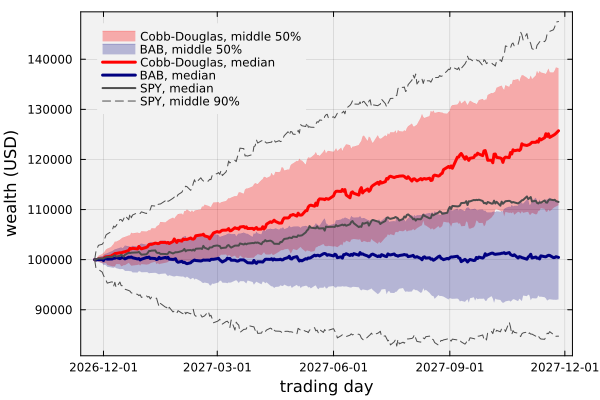

In [5]:
let

    # initialize: the synthetic days -
    days = synthetic_dates;

    # display options used in this cell -
    # fillrange: Shade the area between this series and the given lower series.
    # fillalpha: Set the opacity of the shaded area, from 0 (clear) to 1 (solid).
    # lw: Set the line width in points; 0 draws no line.
    # ls: Set the line style, for example :dash.
    # c: Choose the series color.
    # label: Set the legend entry.
    # bg: Set the plot background color.
    # background_color_outside: Set the background color outside the plotting grid.
    # framestyle: Use a box around the plotting area.
    # fg_legend: Set the legend foreground color; transparent removes its border.
    # legend: Set where the legend goes.
    # yformatter: Write the axis numbers in full, without scientific notation.
    # right_margin: Leave room on the right for the last date label.
    p = plot(days, strategy_band[:, 4], fillrange = strategy_band[:, 2], fillalpha = 0.3, lw = 0, c = :red,
        label = "$(my_weighting), middle 50%", bg = "gray95", background_color_outside = "white", framestyle = :box,
        fg_legend = :transparent, legend = :topleft, yformatter = :plain, right_margin = 5Plots.mm);
    plot!(p, days, second_band[:, 4], fillrange = second_band[:, 2], fillalpha = 0.25, lw = 0, c = :navy,
        label = "$(second_weighting), middle 50%");
    plot!(p, days, strategy_band[:, 3], lw = 3, c = :red, label = "$(my_weighting), median");
    plot!(p, days, second_band[:, 3], lw = 3, c = :navy, label = "$(second_weighting), median");
    plot!(p, days, spy_band[:, 3], lw = 2, c = :gray30, label = "SPY, median");
    plot!(p, days, spy_band[:, 1], lw = 1, ls = :dash, c = :gray30, label = "SPY, middle 90%");
    plot!(p, days, spy_band[:, 5], lw = 1, ls = :dash, c = :gray30, label = "");
    xlabel!(p, "trading day");
    ylabel!(p, "wealth (USD)");

    # return -
    p
end

> __What do we see?__ With the starting settings, the median wealth of the utility basket rose to about USD 126,000 over the year, and the median wealth of BAB stayed near `W0`. The bands of both strategies widen over the year. On the last day, `SPY` ends below `W0` on 49 of the 200 markets.

___

## Task 2: Test Both Strategies with the Five Gates
In this task, we test both strategies with the five gates of the practicum, and measure their losses on the worst markets.

A strategy passes each gate when its scores over the 200 markets meet these limits:
* __Median Sharpe ratio:__ The median Sharpe ratio is at least `sharpe_limit`.
* __Median largest drawdown:__ The median largest drawdown is at most `drawdown_limit`.
* __Failure rate:__ The share of markets that end below `W0` is at most `failure_limit`.
* __Median wealth on the last day:__ The median wealth on the last day is at least that of the comparison. A strategy with fixed estimates faces the 60/40 benchmark of 60% `SPY` and 40% `TLT`. A strategy with updated estimates faces its copy with fixed estimates.
* __Median net present value:__ The median NPV is at least USD 0. The NPV discounts the wealth on the last day at the Treasury bill rate and subtracts `W0`.

The constants `sharpe_limit`, `drawdown_limit`, and `failure_limit` hold the practicum's limits.

First, we find the 200 runs of each strategy with [the `find_runs(...)` function](src/Helper.jl), and the comparison's wealth on the last day of each market. [The `sixty_forty_wealth(...)` function](src/Helper.jl) computes the wealth of the 60/40 benchmark, starting in cash on the first synthetic day.

We store the runs in the `our_runs::DataFrame` and `second_runs::DataFrame` variables, and the comparisons' wealth in the `comparison_terminal::Vector{Float64}` and `second_comparison::Vector{Float64}` variables (USD):

In [6]:
our_runs, second_runs, comparison_terminal, second_comparison = let

    # the 60/40 benchmark's wealth on the last day of each market, from the first synthetic day to the last (USD) -
    number_of_markets = size(spy_closes, 2);
    W_6040_last = zeros(number_of_markets);
    for p ∈ 1:number_of_markets
        W_6040 = sixty_forty_wealth(spy_closes[2:end, p], tlt_closes[2:end, p], synthetic_dates[2:end];
            W0 = W0, half_spread = half_spread);
        W_6040_last[p] = W_6040[end];
    end

    # each strategy's run on each market, in market order, and its comparison (USD) -
    weightings = [my_weighting, second_weighting];
    runs = DataFrame[];
    comparisons = Vector{Float64}[];
    for k ∈ 1:length(weightings)
        strategy_runs = find_runs(stress_runs; picking = my_picking, weighting = weightings[k], hedge = false,
            estimates = my_estimates, seed = my_seed);
        comparison = zeros(nrow(strategy_runs));
        if my_estimates == "fixed"
            # the 60/40 benchmark on the same markets -
            for i ∈ 1:nrow(strategy_runs)
                comparison[i] = W_6040_last[strategy_runs.path_id[i]];
            end
        else
            # the same strategy with fixed estimates, on the same markets -
            fixed_runs = find_runs(stress_runs; picking = my_picking, weighting = weightings[k], hedge = false,
                estimates = "fixed", seed = my_seed);
            for i ∈ 1:nrow(fixed_runs)
                comparison[i] = fixed_runs.terminal[i];
            end
        end
        push!(runs, strategy_runs);
        push!(comparisons, comparison);
    end

    # checks -
    for k ∈ 1:length(runs)
        @assert nrow(runs[k]) == 200 "each strategy must have one saved run on each of the 200 markets"
        @assert runs[k].path_id == runs[1].path_id "both strategies must list the markets in the same order"
        @assert all(comparisons[k] .> 0) "the comparison must have a wealth on every market"
    end

    # return -
    runs[1], runs[2], comparisons[1], comparisons[2]
end;

Let's test both strategies with the five gates. [The `five_gates(...)` function](src/Helper.jl) computes each gate's value and limit as the practicum does, and [the `pretty_table(...)` function](https://ronisbr.github.io/PrettyTables.jl/stable/lib/library/#PrettyTables.pretty_table) displays the gates of the two strategies side by side. We store the gates of our strategy in the `gates_off::DataFrame` variable, and the gates of the second strategy in the `gates_second::DataFrame` variable:

In [7]:
gates_off, gates_second = let

    # the five gates of each strategy -
    gates_off = five_gates(our_runs, comparison_terminal; W0 = W0, sharpe_limit = sharpe_limit,
        drawdown_limit = drawdown_limit, failure_limit = failure_limit);
    gates_second = five_gates(second_runs, second_comparison; W0 = W0, sharpe_limit = sharpe_limit,
        drawdown_limit = drawdown_limit, failure_limit = failure_limit);

    # one row per gate: the value, limit, and result of each strategy -
    df = DataFrame(gate = gates_off.gate, value_ours = gates_off.value, limit_ours = gates_off.limit,
        passed_ours = gates_off.passed, value_second = gates_second.value, limit_second = gates_second.limit,
        passed_second = gates_second.passed);

    # let's display the gates in a table -
    pretty_table(df;
        column_labels = ["gate", my_weighting, "limit", "passed", second_weighting, "limit", "passed"], # column headings
        alignment = [:l, :r, :r, :c, :r, :r, :c], # :l aligns a column left, :r right, and :c in the center
        formatters = [fmt__printf("%.3f", [2, 3, 5, 6])], # three decimals
        table_format = TextTableFormat(borders = text_table_borders__compact), # compact separator characters
        fit_table_in_display_horizontally = false, # keep all columns
        fit_table_in_display_vertically = false # keep all rows
    );

    # return -
    gates_off, gates_second
end;

 ------------------------------------- -------------- ------------ -------- ------------ ------------ --------
  gate                                  Cobb-Douglas        limit   passed          BAB        limit   passed 
 ------------------------------------- -------------- ------------ -------- ------------ ------------ --------
  median Sharpe ratio                          1.100        0.300    true        -0.255        0.300   false
  median largest drawdown                      0.113        0.250    true         0.137        0.250    true
  failure rate                                 0.105        0.100   false         0.485        0.100   false
  median wealth on the last day (USD)     125722.946   106414.434    true    100445.370   106414.434   false
  median NPV (USD)                         20576.046        0.000    true     -3666.705        0.000   false
 ------------------------------------- -------------- ------------ -------- ------------ ------------ --------


> __What do we see?__ With the starting settings, the utility basket passes four of the five gates. It ends below the USD 100,000 starting wealth on 21 of the 200 markets, one more than the failure-rate gate allows. The BAB strategy passes only the median drawdown gate, and it ends below the starting wealth on 97 markets.


To see where the failures come from, let's plot the wealth of both strategies on the last day of each market with [the `histogram(...)` function](https://docs.juliaplots.org/stable/api/#Plots.histogram). The black line marks `W0`, and the bars to its left are the failures. The green dashed line marks the comparison's median:

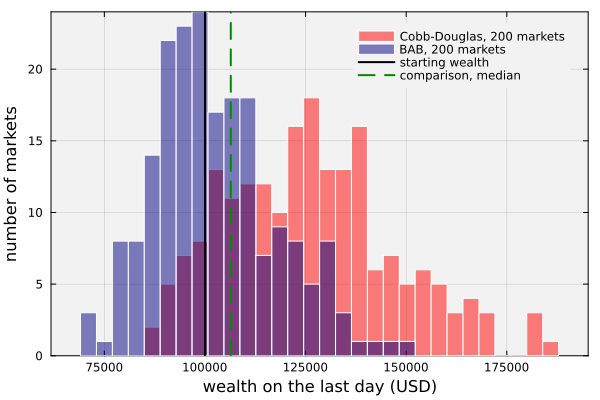

In [8]:
let

    # the same bars for both strategies, from the lowest to the highest wealth on the last day (USD) -
    lowest = min(minimum(our_runs.terminal), minimum(second_runs.terminal));
    highest = max(maximum(our_runs.terminal), maximum(second_runs.terminal));
    edges = range(lowest, highest, length = 31); # the edges of 30 bars (USD)

    # display options used in this cell (see Task 1 for the others) -
    # bins: Set the edges of the bars.
    # lc: Set the color of the bar outlines.
    p = histogram(our_runs.terminal, bins = edges, c = :red, fillalpha = 0.5, lc = :white,
        label = "$(my_weighting), 200 markets", bg = "gray95", background_color_outside = "white", framestyle = :box,
        fg_legend = :transparent, legend = :topright, xformatter = :plain);
    histogram!(p, second_runs.terminal, bins = edges, c = :navy, fillalpha = 0.5, lc = :white,
        label = "$(second_weighting), 200 markets");
    vline!(p, [W0], lw = 2, c = :black, label = "starting wealth");
    vline!(p, [median(comparison_terminal)], lw = 2, ls = :dash, c = :green4, label = "comparison, median");
    xlabel!(p, "wealth on the last day (USD)");
    ylabel!(p, "number of markets");

    # return -
    p
end

The histogram counts the failures, but it does not show how much each strategy loses on its worst markets. Let's measure the loss, `W0` minus the wealth on the last day, with the value at risk (VaR) and the conditional value at risk (CVaR). The practicum does not gate these numbers.

[The `tail_losses(...)` function](src/Helper.jl) computes both numbers at the level `tail_level`. Only a share `1 - tail_level` of the markets lose more than the VaR. The CVaR is the average loss on those markets:

In [9]:
let

    # the VaR and CVaR of the loss of each strategy (USD) -
    tail_ours = tail_losses(our_runs.terminal; W0 = W0, level = tail_level);
    tail_second = tail_losses(second_runs.terminal; W0 = W0, level = tail_level);

    # one row per number: the value for each strategy (USD) -
    df = DataFrame(measure = ["value at risk (USD)", "conditional value at risk (USD)"],
        ours = [tail_ours.VaR, tail_ours.CVaR], second = [tail_second.VaR, tail_second.CVaR]);

    # checks -
    @assert tail_ours.CVaR >= tail_ours.VaR && tail_second.CVaR >= tail_second.VaR "the CVaR averages the losses at or above the VaR"

    # let's display the numbers in a table -
    pretty_table(df;
        column_labels = ["loss at level $(tail_level)", my_weighting, second_weighting], # column headings
        alignment = [:l, :r, :r], # :l aligns a column left, and :r right
        formatters = [fmt__printf("%.0f", [2, 3])], # whole USD
        table_format = TextTableFormat(borders = text_table_borders__compact), # compact separator characters
        fit_table_in_display_horizontally = false, # keep all columns
        fit_table_in_display_vertically = false # keep all rows
    );
end

 --------------------------------- -------------- -------
  loss at level 0.95                Cobb-Douglas     BAB 
 --------------------------------- -------------- -------
  value at risk (USD)                       5895   20674
  conditional value at risk (USD)           9277   24241
 --------------------------------- -------------- -------


> __What do we see?__ With the starting settings, the utility basket loses more than its VaR of USD 5,895 on 10 of the 200 markets. Its CVaR, the average loss on those 10 markets, is USD 9,277, less than 10% of `W0`. The BAB strategy loses more on its worst markets, with a VaR of USD 20,674 and a CVaR of USD 24,241.


___

## Task 3: Turn the Market Hedge On
In this task, we test our strategy with the market hedge on, and change nothing else.

The [trading engine details](engine/CHEME-5660-L15a-Trading-Engine-Fall-2026.ipynb) show how the hedge limits the market sensitivity of the portfolio. The comparison of the fourth gate stays the same, except that the copy with fixed estimates also has the hedge on.

We store the hedged runs in the `hedged_runs::DataFrame` variable and their comparison in the `hedged_comparison::Vector{Float64}` variable (USD):

In [10]:
hedged_runs, hedged_comparison = let

    # our strategy with the hedge on, on each market, in market order -
    hedged_runs = find_runs(stress_runs; picking = my_picking, weighting = my_weighting, hedge = true,
        estimates = my_estimates, seed = my_seed);

    # the comparison: the same 60/40 benchmark, or the hedged copy with fixed estimates (USD) -
    number_of_markets = nrow(hedged_runs);
    hedged_comparison = zeros(number_of_markets);
    if my_estimates == "fixed"
        hedged_comparison = copy(comparison_terminal);
    else
        hedged_fixed_runs = find_runs(stress_runs; picking = my_picking, weighting = my_weighting, hedge = true,
            estimates = "fixed", seed = my_seed);
        for k ∈ 1:nrow(hedged_fixed_runs)
            hedged_comparison[k] = hedged_fixed_runs.terminal[k];
        end
    end

    # checks -
    @assert number_of_markets == 200 "the hedged strategy must have one saved run on each of the 200 markets"
    @assert hedged_runs.path_id == our_runs.path_id "both strategies must list the markets in the same order"

    # return -
    hedged_runs, hedged_comparison
end;

Let's plot each market's wealth on the last day with the hedge on against the wealth with the hedge off, with the [`scatter(...)` function](https://docs.juliaplots.org/stable/api/#Plots.scatter). A point above the diagonal line is a market on which the hedge ended with more wealth:

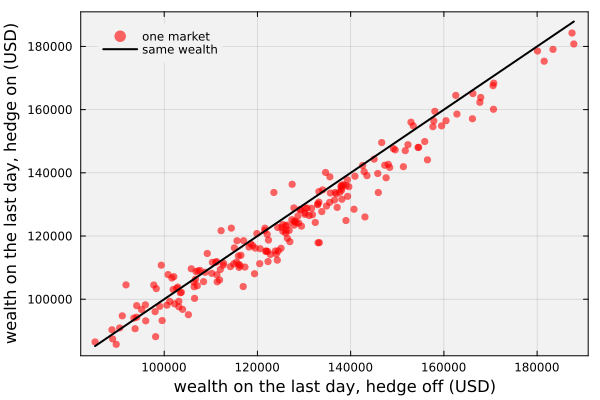

In [11]:
let

    # the range of both axes, so the diagonal line spans the points (USD) -
    lowest = min(minimum(our_runs.terminal), minimum(hedged_runs.terminal));
    highest = max(maximum(our_runs.terminal), maximum(hedged_runs.terminal));

    # display options used in this cell (see Task 1 for the others) -
    # ms: Set the marker size in points.
    # msw: Set the marker outline width in points.
    # ma: Set the marker opacity, from 0 (clear) to 1 (solid).
    p = scatter(our_runs.terminal, hedged_runs.terminal, ms = 4, msw = 0, c = :red, ma = 0.6, label = "one market",
        bg = "gray95", background_color_outside = "white", framestyle = :box, fg_legend = :transparent,
        legend = :topleft, xformatter = :plain, yformatter = :plain);
    plot!(p, [lowest, highest], [lowest, highest], lw = 2, c = :black, label = "same wealth");
    xlabel!(p, "wealth on the last day, hedge off (USD)");
    ylabel!(p, "wealth on the last day, hedge on (USD)");

    # return -
    p
end

Finally, let's compute the five gates with the hedge on, and display them next to the gates without the hedge:

In [12]:
let

    # the five gates of the hedged strategy -
    gates_on = five_gates(hedged_runs, hedged_comparison; W0 = W0, sharpe_limit = sharpe_limit,
        drawdown_limit = drawdown_limit, failure_limit = failure_limit);

    # one row per gate: the value, limit, and result without and with the hedge -
    df = DataFrame(gate = gates_off.gate, value_off = gates_off.value, limit_off = gates_off.limit,
        passed_off = gates_off.passed, value_on = gates_on.value, limit_on = gates_on.limit, passed_on = gates_on.passed);

    # let's display the gates in a table -
    pretty_table(df;
        column_labels = ["gate", "hedge off", "limit", "passed", "hedge on", "limit", "passed"], # column headings
        alignment = [:l, :r, :r, :c, :r, :r, :c], # :l aligns a column left, :r right, and :c in the center
        formatters = [fmt__printf("%.3f", [2, 3, 5, 6])], # three decimals
        table_format = TextTableFormat(borders = text_table_borders__compact), # compact separator characters
        fit_table_in_display_horizontally = false, # keep all columns
        fit_table_in_display_vertically = false # keep all rows
    );
end

 ------------------------------------- ------------ ------------ -------- ------------ ------------ --------
  gate                                   hedge off        limit   passed     hedge on        limit   passed 
 ------------------------------------- ------------ ------------ -------- ------------ ------------ --------
  median Sharpe ratio                        1.100        0.300    true         0.953        0.300    true
  median largest drawdown                    0.113        0.250    true         0.106        0.250    true
  failure rate                               0.105        0.100   false         0.120        0.100   false
  median wealth on the last day (USD)   125722.946   106414.434    true    121740.272   106414.434    true
  median NPV (USD)                       20576.046        0.000    true     16756.417        0.000    true
 ------------------------------------- ------------ ------------ -------- ------------ ------------ --------


> __What do we see?__ With the starting settings, the hedge lowered the median drawdown of the utility basket to 10.6% and its median wealth on the last day to USD 121,740. Across the menu, the hedged run ends with more wealth in 30,864 of the 75,600 pairs of runs that differ only in the hedge. The hedged run has the smaller drawdown in 41,852 pairs.

___

## Summary
In this example, we stress-tested the utility basket and BAB on 200 synthetic markets and tested both strategies with the five gates. Then we tested the utility basket again with the market hedge on.

> __Key Takeaways:__
>
> * __A stress test shows a range of outcomes:__ We ran both strategies on 200 synthetic markets that share the real history and differ in the next year. The percentiles of their wealth showed how far the outcome can spread. Even `SPY` ended below the starting wealth on 49 of the 200 markets.
> * __Most strategies fail the failure-rate gate:__ We tested both strategies with the five gates. The utility basket passed four gates and ended below the starting wealth on 21 of the 200 markets, one more than the failure-rate gate allows. With the practicum's settings, only 23 of the 756 stress tests passed all five gates.
> * __The hedge lowers the drawdown more often than it adds wealth:__ We ran the utility basket with the market hedge on. Across the menu, the hedged run had the smaller drawdown in 41,852 of the 75,600 pairs of runs that differ only in the hedge. It ended with more wealth in only 30,864 pairs.

Next time, we'll trade a strategy in a paper account at live market prices.

## Disclaimer and Risks
__This content is offered solely for training and informational purposes__. No offer or solicitation to buy or sell securities or derivative products or any investment or trading advice or strategy is made, given, or endorsed by the teaching team.

__Trading involves risk__. Carefully review your financial situation before investing in securities, futures contracts, options, or commodity interests. Past performance, whether actual or indicated by historical tests of strategies, is no guarantee of future performance or success.

Trading is generally inappropriate for someone with limited resources, investment or trading experience, or a low-risk tolerance. Only risk capital that is not required for living expenses should be used.

__You are fully responsible for any investment or trading decisions you make__. Such decisions should be based solely on evaluating your financial circumstances, investment or trading objectives, risk tolerance, and liquidity needs.

___